# Olist 營運分析 EDA

這份 notebook 以 Olist 電商資料集為基礎，整理出適合營運決策的探索式分析與圖表，重點聚焦在：

- 訂單成長與營收結構
- 客戶回購與訂單品質
- 履約效率與顧客滿意度
- 地區與品類的營運機會點

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

COLORS = {
    "navy": "#1f3c5b",
    "blue": "#2f6f9f",
    "teal": "#4da6a6",
    "sand": "#d9b26f",
    "orange": "#d97b2d",
    "red": "#b24c3d",
}


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

COLORS = {
    "navy": "#1f3c5b",
    "blue": "#2f6f9f",
    "teal": "#4da6a6",
    "sand": "#d9b26f",
    "orange": "#d97b2d",
    "red": "#b24c3d",
}

In [3]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw"

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

dfs = {name: pd.read_csv(data_dir / filename) for name, filename in files.items()}

customers = dfs["customers"].copy()
geolocation = dfs["geolocation"].copy()
order_items = dfs["order_items"].copy()
order_payments = dfs["order_payments"].copy()
order_reviews = dfs["order_reviews"].copy()
orders = dfs["orders"].copy()
products = dfs["products"].copy()
sellers = dfs["sellers"].copy()
category_translation = dfs["category_translation"].copy()

for col in [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
orders["purchase_date"] = orders["order_purchase_timestamp"].dt.date

print(f"Project root: {project_root}")
print(f"Data directory: {data_dir}")


Project root: D:\Sourcecode\Dev\operations-analytics
Data directory: D:\Sourcecode\Dev\operations-analytics\data\raw


## 1. 資料概覽

In [4]:
overview = pd.DataFrame(
    [
        {
            "table": name,
            "rows": df.shape[0],
            "columns": df.shape[1],
            "missing_cells": int(df.isna().sum().sum()),
        }
        for name, df in dfs.items()
    ]
).sort_values("rows", ascending=False)

overview


,table,rows,columns,missing_cells
1,geolocation,1000163,5,0
2,order_items,112650,7,0
3,order_payments,103886,5,0
0,customers,99441,5,0
5,orders,99441,8,4908
4,order_reviews,99224,7,145903
6,products,32951,9,2448
7,sellers,3095,4,0
8,category_translation,71,2,0


In [5]:
missing_summary = (
    pd.concat(
        {
            name: (df.isna().mean() * 100).rename("missing_pct")
            for name, df in dfs.items()
        }
    )
    .reset_index()
    .rename(columns={"level_0": "table", "level_1": "column"})
    .query("missing_pct > 0")
    .sort_values(["missing_pct", "table"], ascending=[False, True])
)

missing_summary.head(20)


,table,column,missing_pct
25,order_reviews,review_comment_title,88.34
26,order_reviews,review_comment_message,58.70
35,orders,order_delivered_customer_date,2.98
38,products,product_category_name,1.85
39,products,product_name_lenght,1.85
40,products,product_description_lenght,1.85
41,products,product_photos_qty,1.85
34,orders,order_delivered_carrier_date,1.79
33,orders,order_approved_at,0.16
42,products,product_weight_g,0.01


## 2. 建立分析主表

將訂單、客戶、付款、商品與評論資料整合成營運分析主表。

In [12]:
payment_agg = (
    order_payments.groupby("order_id", as_index=False)
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max"),
    )
)

item_agg = (
    order_items.groupby("order_id", as_index=False)
    .agg(
        item_qty=("order_item_id", "count"),
        item_price=("price", "sum"),
        freight_value=("freight_value", "sum"),
        seller_count=("seller_id", "nunique"),
    )
)

review_agg = (
    order_reviews.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

order_category = (
    order_items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(category_translation, on="product_category_name", how="left")
    .groupby(["order_id", "product_category_name_english"], as_index=False)
    .size()
    .rename(columns={"size": "lines"})
    .sort_values(["order_id", "lines"], ascending=[True, False])
    .drop_duplicates("order_id")
)

fact_orders = (
    orders.merge(
        customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
        on="customer_id",
        how="left",
    )
    .merge(payment_agg, on="order_id", how="left")
    .merge(item_agg, on="order_id", how="left")
    .merge(review_agg, on="order_id", how="left")
    .merge(order_category[["order_id", "product_category_name_english"]], on="order_id", how="left")
)

fact_orders["delivery_days"] = (
    fact_orders["order_delivered_customer_date"] - fact_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400
fact_orders["approval_hours"] = (
    fact_orders["order_approved_at"] - fact_orders["order_purchase_timestamp"]
).dt.total_seconds() / 3600
fact_orders["delay_days"] = (
    fact_orders["order_delivered_customer_date"] - fact_orders["order_estimated_delivery_date"]
).dt.days
fact_orders["is_late"] = fact_orders["delay_days"] > 0
fact_orders["freight_share"] = fact_orders["freight_value"] / fact_orders["item_price"]
fact_orders["has_review"] = fact_orders["review_score"].notna()

delivered_orders = fact_orders.query("order_status == 'delivered'").copy()

fact_orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_month,purchase_date,customer_unique_id,customer_city,customer_state,payment_value,payment_installments,item_qty,item_price,freight_value,seller_count,review_score,product_category_name_english,delivery_days,approval_hours,delay_days,is_late,freight_share,has_review
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,2017-10-02,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,38.71,1.00,1.00,29.99,8.72,1.00,4.00,housewares,8.44,0.18,-8.00,False,0.29,True
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,2018-07-24,af07308b275d755c9edb36a90c618231,barreiras,BA,141.46,1.00,1.00,118.70,22.76,1.00,4.00,perfumery,13.78,30.71,-6.00,False,0.19,True
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,2018-08-08,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,179.12,3.00,1.00,159.90,19.22,1.00,5.00,auto,9.39,0.28,-18.00,False,0.12,True
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,2017-11-18,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,72.20,1.00,1.00,45.00,27.20,1.00,5.00,pet_shop,13.21,0.30,-13.00,False,0.60,True
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,2018-02-13,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,28.62,1.00,1.00,19.90,8.72,1.00,5.00,stationery,2.87,1.03,-10.00,False,0.44,True


## 3. 核心營運 KPI

In [11]:
customer_order_counts = (
    fact_orders.groupby("customer_unique_id", as_index=False)
    .agg(order_count=("order_id", "nunique"))
)

kpis = pd.Series(
    {
        "orders": fact_orders["order_id"].nunique(),
        "delivered_orders": delivered_orders["order_id"].nunique(),
        "customers": customers["customer_unique_id"].nunique(),
        "sellers": sellers["seller_id"].nunique(),
        "gmv": delivered_orders["payment_value"].sum(),
        "avg_order_value": delivered_orders["payment_value"].mean(),
        "median_order_value": delivered_orders["payment_value"].median(),
        "repeat_customer_rate": (customer_order_counts["order_count"] >= 2).mean(),
        "cancel_rate": (fact_orders["order_status"] == "canceled").mean(),
        "unavailable_rate": (fact_orders["order_status"] == "unavailable").mean(),
        "avg_delivery_days": delivered_orders["delivery_days"].mean(),
        "late_delivery_rate": delivered_orders["is_late"].mean(),
        "avg_review_score": delivered_orders["review_score"].mean(),
        "avg_freight_share": delivered_orders["freight_share"].replace([np.inf, -np.inf], np.nan).mean(),
    }
).rename("value")

kpis.to_frame()
#output normal number
# pd.options.display.float_format = "{:,.2f}".format
kpi_display = pd.DataFrame({
    "KPI": kpis.index,
    "Value": [
        f"{kpis['orders']:,.0f}",
        f"{kpis['delivered_orders']:,.0f}",
        f"{kpis['customers']:,.0f}",
        f"{kpis['sellers']:,.0f}",
        f"{kpis['gmv']:,.2f}",
        f"{kpis['avg_order_value']:,.2f}",
        f"{kpis['median_order_value']:,.2f}",
        f"{kpis['repeat_customer_rate']:.2%}",
        f"{kpis['cancel_rate']:.2%}",
        f"{kpis['unavailable_rate']:.2%}",
        f"{kpis['avg_delivery_days']:.2f}",
        f"{kpis['late_delivery_rate']:.2%}",
        f"{kpis['avg_review_score']:.2f}",
        f"{kpis['avg_freight_share']:.2%}",
    ]
})

kpi_display

,KPI,Value
0,orders,"99,441"
1,delivered_orders,"96,478"
2,customers,"96,096"
3,sellers,"3,095"
4,gmv,"15,422,461.77"
5,avg_order_value,159.86
6,median_order_value,105.28
7,repeat_customer_rate,3.12%
8,cancel_rate,0.63%
9,unavailable_rate,0.61%


## 4. 訂單狀態與月度趨勢

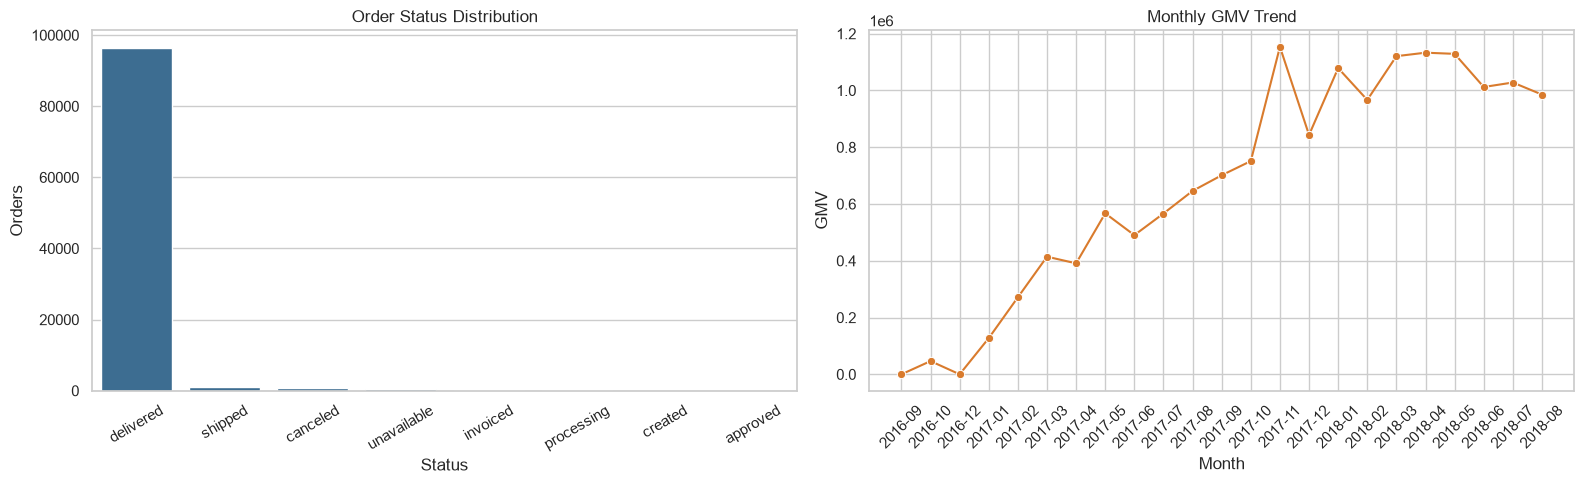

,purchase_month,orders,customers,gmv,aov,mom_gmv_growth
11,2017-09,4150,4083,"701,169.99",168.96,0.09
12,2017-10,4478,4417,"751,140.27",167.74,0.07
13,2017-11,7289,7183,"1,153,528.05",158.26,0.54
14,2017-12,5513,5450,"843,199.17",152.95,-0.27
15,2018-01,7069,6974,"1,078,606.86",152.58,0.28
16,2018-02,6555,6400,"966,510.88",147.45,-0.10
17,2018-03,7003,6914,"1,120,678.00",160.03,0.16
18,2018-04,6798,6744,"1,132,933.95",166.66,0.01
19,2018-05,6749,6693,"1,128,836.69",167.26,-0.00
20,2018-06,6099,6061,"1,012,090.68",165.94,-0.10


In [9]:
status_counts = fact_orders["order_status"].value_counts().rename_axis("order_status").reset_index(name="orders")

monthly_metrics = (
    delivered_orders.groupby("purchase_month", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        customers=("customer_unique_id", "nunique"),
        gmv=("payment_value", "sum"),
        aov=("payment_value", "mean"),
    )
)
monthly_metrics["mom_gmv_growth"] = monthly_metrics["gmv"].pct_change()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=status_counts, x="order_status", y="orders", ax=axes[0], color=COLORS["blue"])
axes[0].set_title("Order Status Distribution")
axes[0].set_xlabel("Status")
axes[0].set_ylabel("Orders")
axes[0].tick_params(axis="x", rotation=30)

sns.lineplot(data=monthly_metrics, x="purchase_month", y="gmv", marker="o", ax=axes[1], color=COLORS["orange"])
axes[1].set_title("Monthly GMV Trend")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("GMV")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

monthly_metrics.tail(12)


## 5. 物流表現與顧客評分

C:\Users\harry\AppData\Local\Temp\ipykernel_42740\3170973249.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


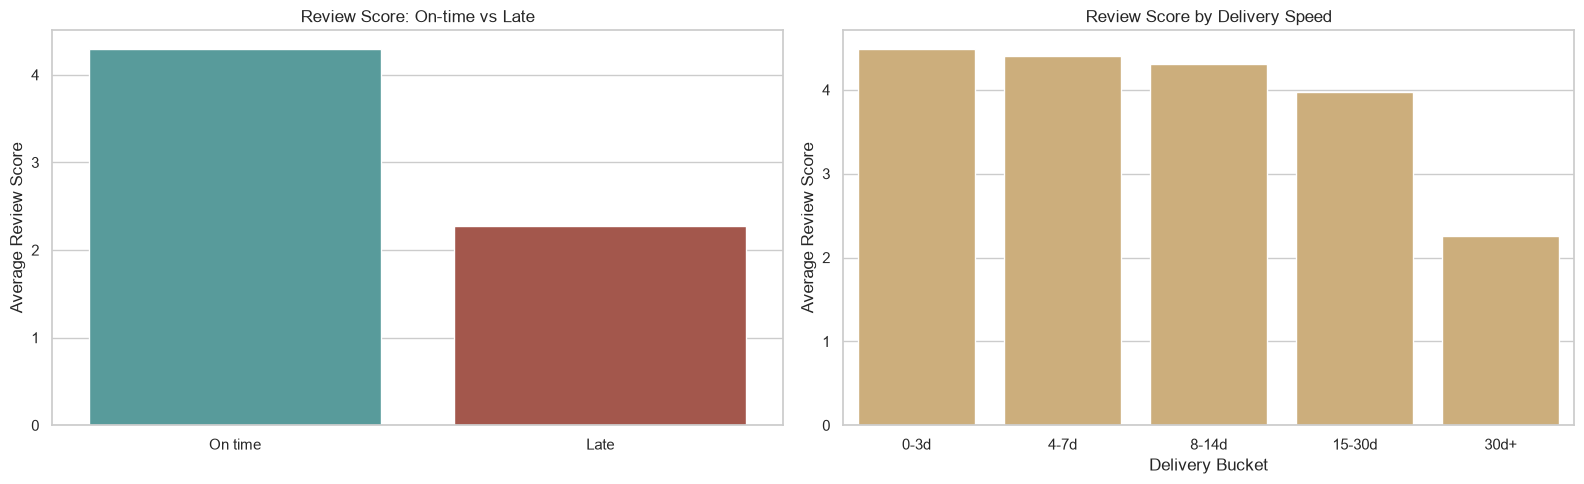

,delivery_bucket,orders,avg_review_score,late_rate
0,0-3d,4753,4.48,0.00
1,4-7d,21293,4.40,0.00
2,8-14d,40212,4.31,0.01
3,15-30d,25662,3.97,0.10
4,30d+,4550,2.25,0.79


In [13]:
review_by_late = (
    delivered_orders.groupby("is_late", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        avg_review_score=("review_score", "mean"),
        avg_order_value=("payment_value", "mean"),
    )
)

delivery_bucket_order = ["0-3d", "4-7d", "8-14d", "15-30d", "30d+"]
delivery_bucket_df = delivered_orders.copy()
delivery_bucket_df["delivery_bucket"] = pd.cut(
    delivery_bucket_df["delivery_days"],
    bins=[0, 3, 7, 14, 30, 999],
    labels=delivery_bucket_order,
)

delivery_bucket_summary = (
    delivery_bucket_df.groupby("delivery_bucket", as_index=False, observed=False)
    .agg(
        orders=("order_id", "nunique"),
        avg_review_score=("review_score", "mean"),
        late_rate=("is_late", "mean"),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    data=review_by_late.assign(is_late=review_by_late["is_late"].map({False: "On time", True: "Late"})),
    x="is_late",
    y="avg_review_score",
    ax=axes[0],
    palette=[COLORS["teal"], COLORS["red"]],
)
axes[0].set_title("Review Score: On-time vs Late")
axes[0].set_xlabel("")
axes[0].set_ylabel("Average Review Score")

sns.barplot(
    data=delivery_bucket_summary,
    x="delivery_bucket",
    y="avg_review_score",
    ax=axes[1],
    color=COLORS["sand"],
)
axes[1].set_title("Review Score by Delivery Speed")
axes[1].set_xlabel("Delivery Bucket")
axes[1].set_ylabel("Average Review Score")

plt.tight_layout()
plt.show()

delivery_bucket_summary


## 6. 地區營運分析

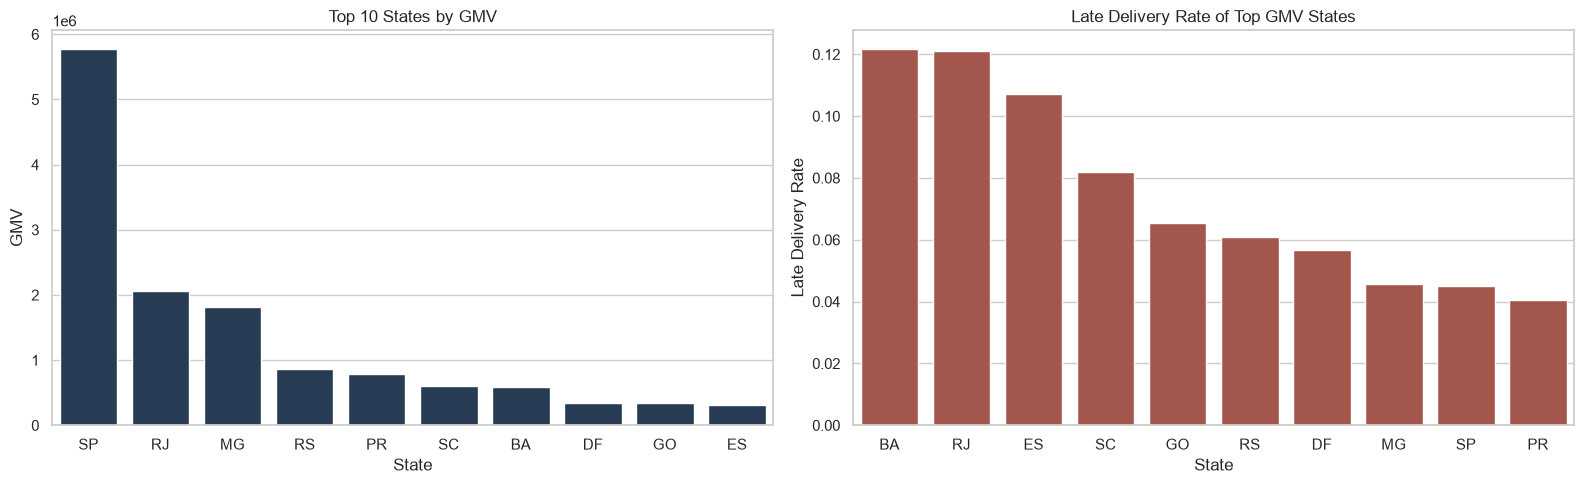

,customer_state,orders,gmv,aov,review_score,late_rate,delivery_days,freight_share
25,SP,40501,"5,770,266.19",142.48,4.25,0.04,8.76,0.25
18,RJ,12350,"2,055,690.45",166.45,3.97,0.12,15.31,0.32
10,MG,11354,"1,819,277.61",160.23,4.19,0.05,12.01,0.32
22,RS,5345,"861,802.40",161.24,4.19,0.06,15.30,0.34
17,PR,4923,"781,919.55",158.83,4.24,0.04,11.99,0.33
23,SC,3546,"595,208.40",167.85,4.13,0.08,14.95,0.33
4,BA,3256,"591,270.60",181.59,3.93,0.12,19.34,0.39
6,DF,2080,"346,146.17",166.42,4.13,0.06,12.97,0.33
8,GO,1957,"334,294.22",170.82,4.10,0.07,15.61,0.34
7,ES,1995,"317,682.65",159.24,4.08,0.11,15.79,0.35


In [14]:
state_metrics = (
    delivered_orders.groupby("customer_state", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        gmv=("payment_value", "sum"),
        aov=("payment_value", "mean"),
        review_score=("review_score", "mean"),
        late_rate=("is_late", "mean"),
        delivery_days=("delivery_days", "mean"),
        freight_share=("freight_share", "mean"),
    )
    .sort_values("gmv", ascending=False)
)

top_states = state_metrics.head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=top_states, x="customer_state", y="gmv", ax=axes[0], color=COLORS["navy"])
axes[0].set_title("Top 10 States by GMV")
axes[0].set_xlabel("State")
axes[0].set_ylabel("GMV")

late_view = top_states.sort_values("late_rate", ascending=False)
sns.barplot(data=late_view, x="customer_state", y="late_rate", ax=axes[1], color=COLORS["red"])
axes[1].set_title("Late Delivery Rate of Top GMV States")
axes[1].set_xlabel("State")
axes[1].set_ylabel("Late Delivery Rate")

plt.tight_layout()
plt.show()

top_states


## 7. 品類營運分析

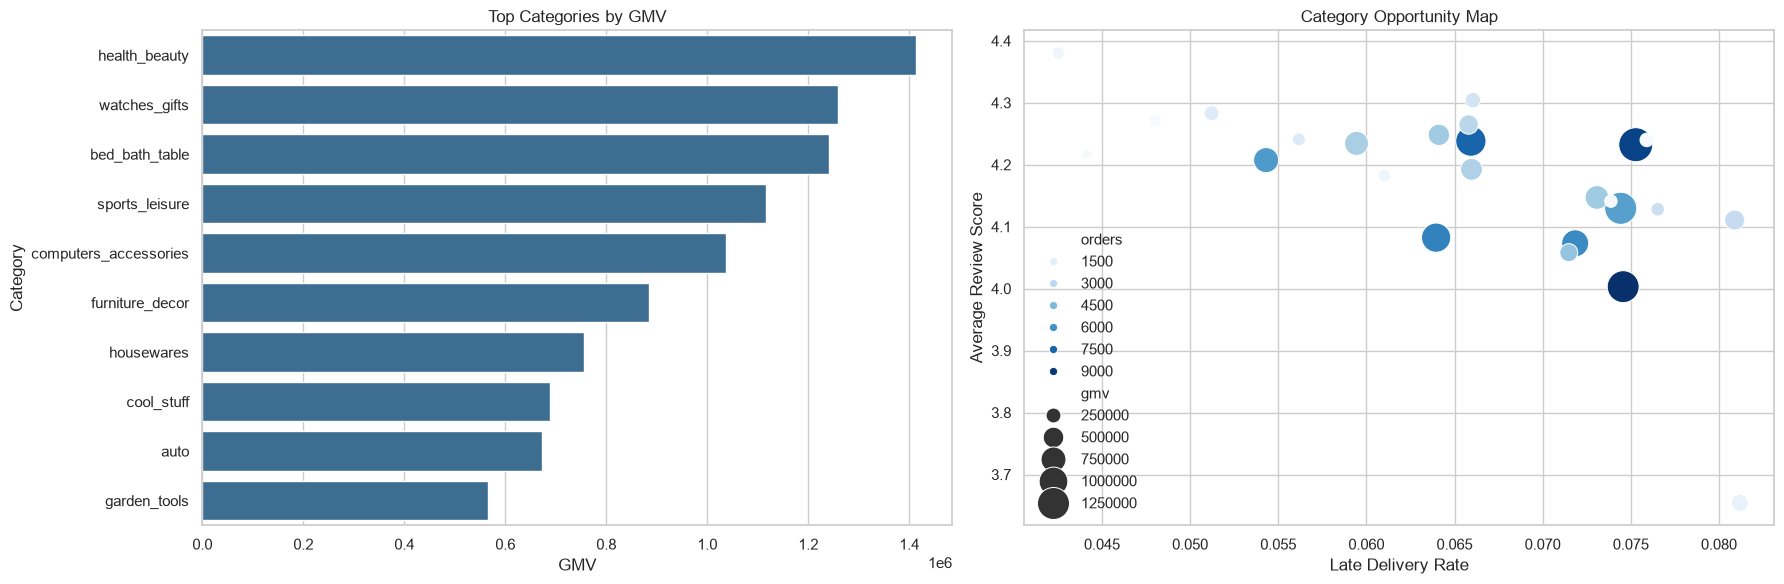

,product_category_name_english,orders,gmv,review_score,late_rate,freight_share
57,office_furniture,1244,"333,916.11",3.65,0.08,0.26
6,baby,2794,"473,907.38",4.11,0.08,0.29
26,electronics,2509,"202,444.19",4.13,0.08,0.69
56,musical_instruments,606,"202,032.91",4.24,0.08,0.25
43,health_beauty,8621,"1,413,962.84",4.23,0.08,0.28
7,bed_bath_table,9240,"1,241,401.11",4.00,0.07,0.27
70,watches_gifts,5455,"1,257,930.55",4.13,0.07,0.17
17,construction_tools_construction,731,"163,966.98",4.14,0.07,0.34
5,auto,3804,"671,719.35",4.15,0.07,0.32
39,furniture_decor,6208,"884,646.29",4.07,0.07,0.32


In [15]:
category_metrics = (
    delivered_orders.groupby("product_category_name_english", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        gmv=("payment_value", "sum"),
        review_score=("review_score", "mean"),
        late_rate=("is_late", "mean"),
        freight_share=("freight_share", "mean"),
    )
    .query("orders >= 500")
    .sort_values("gmv", ascending=False)
)

top_categories = category_metrics.head(10)
risk_categories = category_metrics.sort_values(["late_rate", "review_score"], ascending=[False, True]).head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(data=top_categories, y="product_category_name_english", x="gmv", ax=axes[0], color=COLORS["blue"])
axes[0].set_title("Top Categories by GMV")
axes[0].set_xlabel("GMV")
axes[0].set_ylabel("Category")

sns.scatterplot(
    data=category_metrics,
    x="late_rate",
    y="review_score",
    size="gmv",
    hue="orders",
    palette="Blues",
    ax=axes[1],
    sizes=(50, 600),
)
axes[1].set_title("Category Opportunity Map")
axes[1].set_xlabel("Late Delivery Rate")
axes[1].set_ylabel("Average Review Score")

plt.tight_layout()
plt.show()

risk_categories


In [19]:
order_payments.isna().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

## 8. 付款方式與客單價

C:\Users\harry\AppData\Local\Temp\ipykernel_42740\589336432.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_mix, x="payment_type", y="value", ax=axes[0], palette=[COLORS["navy"], COLORS["sand"], COLORS["teal"], COLORS["orange"]])


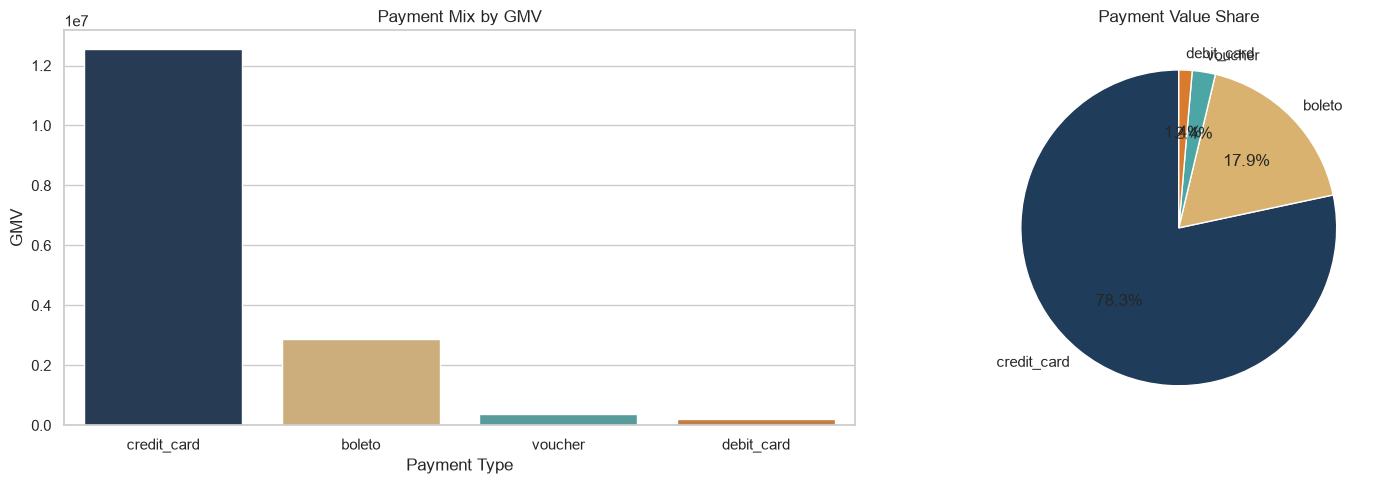

,payment_type,orders,value,avg_installments,value_share
1,credit_card,76505,"12,542,084.19",3.51,0.78
0,boleto,19784,"2,869,361.27",1.00,0.18
3,voucher,3866,"379,436.87",1.00,0.02
2,debit_card,1528,"217,989.79",1.00,0.01


In [35]:
payment_mix = (
    order_payments.loc[order_payments["payment_type"] != "not_defined"]
    .groupby("payment_type", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        value=("payment_value", "sum"),
        avg_installments=("payment_installments", "mean"),
    )
    .sort_values("value", ascending=False)
)
payment_mix["value_share"] = payment_mix["value"] / payment_mix["value"].sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=payment_mix, x="payment_type", y="value", ax=axes[0], palette=[COLORS["navy"], COLORS["sand"], COLORS["teal"], COLORS["orange"]])
axes[0].set_title("Payment Mix by GMV")
axes[0].set_xlabel("Payment Type")
axes[0].set_ylabel("GMV")

axes[1].pie(
    payment_mix["value"],
    labels=payment_mix["payment_type"],
    autopct="%1.1f%%",
    startangle=90,
    colors=[COLORS["navy"], COLORS["sand"], COLORS["teal"], COLORS["orange"]],
)
axes[1].set_title("Payment Value Share")

plt.tight_layout()
plt.show()

payment_mix


## 9. 客戶回購分析

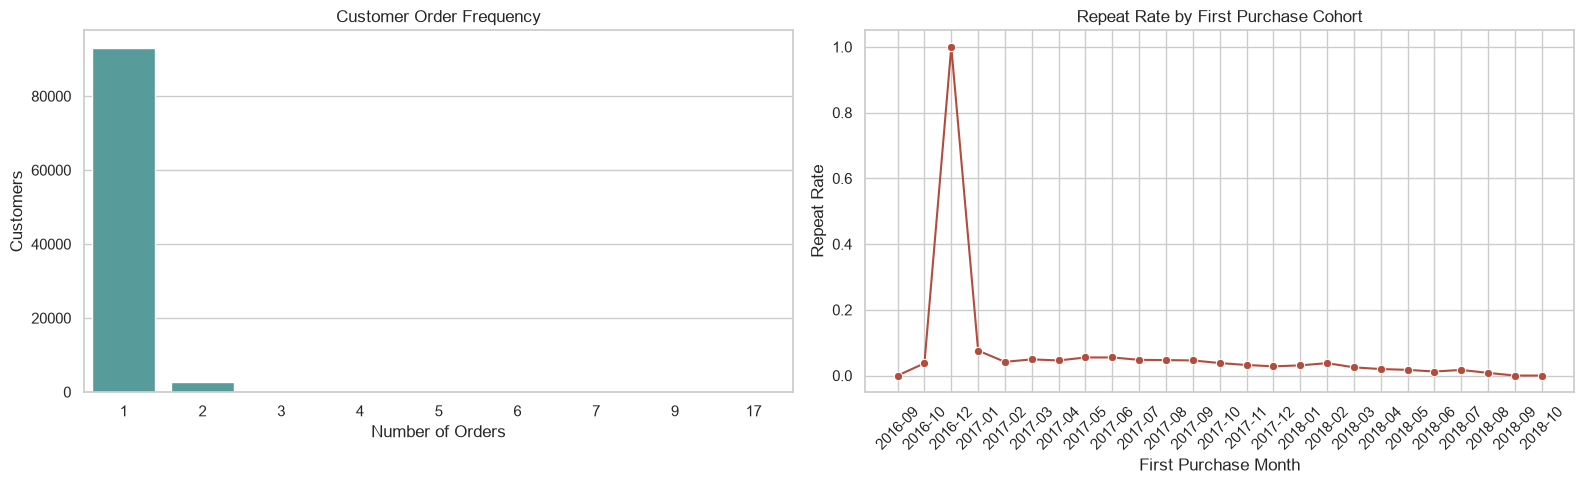

,first_month,new_customers,repeat_rate
13,2017-11,7304,0.03
14,2017-12,5487,0.03
15,2018-01,7025,0.03
16,2018-02,6451,0.04
17,2018-03,6965,0.02
18,2018-04,6711,0.02
19,2018-05,6622,0.02
20,2018-06,5940,0.01
21,2018-07,6071,0.02
22,2018-08,6271,0.01


In [17]:
repeat_distribution = (
    customer_order_counts["order_count"].value_counts().sort_index().rename_axis("order_count").reset_index(name="customers")
)
repeat_distribution["customer_share"] = repeat_distribution["customers"] / repeat_distribution["customers"].sum()

cohort_base = (
    fact_orders.sort_values("order_purchase_timestamp")
    .groupby("customer_unique_id", as_index=False)
    .agg(
        first_purchase=("order_purchase_timestamp", "min"),
        order_count=("order_id", "nunique"),
    )
)
cohort_base["first_month"] = cohort_base["first_purchase"].dt.to_period("M").astype(str)

cohort_summary = (
    cohort_base.groupby("first_month", as_index=False)
    .agg(
        new_customers=("customer_unique_id", "count"),
        repeat_rate=("order_count", lambda s: (s >= 2).mean()),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=repeat_distribution.head(10), x="order_count", y="customers", ax=axes[0], color=COLORS["teal"])
axes[0].set_title("Customer Order Frequency")
axes[0].set_xlabel("Number of Orders")
axes[0].set_ylabel("Customers")

sns.lineplot(data=cohort_summary, x="first_month", y="repeat_rate", marker="o", ax=axes[1], color=COLORS["red"])
axes[1].set_title("Repeat Rate by First Purchase Cohort")
axes[1].set_xlabel("First Purchase Month")
axes[1].set_ylabel("Repeat Rate")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

cohort_summary.tail(12)


## 10. 營運結論

建議優先關注的方向：

1. 提高回購率：大部分客戶只購買一次，應建立首購後的再行銷與會員機制。
2. 控制晚到率：配送延遲會顯著拉低評分，是體驗與留存的關鍵槓桿。
3. 州別差異管理：高 GMV 州別如 `SP` 可擴大經營，高晚到州別如 `RJ`、`BA` 需優先優化履約。
4. 品類精細化：高 GMV 但低評分或高晚到的品類，適合專項改善物流、包裝與客服。
5. 追蹤運費壓力：高運費占比會侵蝕體驗與利潤，適合搭配免運門檻或商品組合策略。